## Exploratory Data Analyiss - Household Electricity Consumption

## Objectives 
1. Analyse electricity consumption pattern over time. 
2. Identify periods of high or changing consumption.
3. Explore trends across the available measurements.
4. Assess whether the data supports forecasting 

## Inputs 
- 'cleaned_data_power_consumption' 

## Outputs 
- Charts and key findings to support the dashboard and reccomendation.


In [ ]:
%matplotlib inline


#Data handling
import pandas as pd
import numpy as np

#Visuals 
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#Load cleaned dataset 
#parse_dates turns the datetiem column into real dates
df = pd.read_csv(
    "../cleaned_data_power_consumption",
    parse_dates=["datetime"],
    index_col="datetime"
)

#Check first 5 rows 
df.head()


,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,0.5278,16.8611
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,6.7167,16.8667
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,1.4333,16.6833
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,16.7833
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,0.4167,17.2167


In [3]:
#Number of rows and columns 
print("Shape:", df.shape)

#Column types 
df.info()

#First and last time stamps to see the data range covered
print("Start:", df.index.min())
print("End:", df.index.max())


Shape: (34168, 7)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34168 entries, 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   global_active_power    34168 non-null  float64
 1   global_reactive_power  34168 non-null  float64
 2   voltage                34168 non-null  float64
 3   global_intensity       34168 non-null  float64
 4   sub_metering_1         34168 non-null  float64
 5   sub_metering_2         34168 non-null  float64
 6   sub_metering_3         34168 non-null  float64
dtypes: float64(7)
memory usage: 2.1 MB
Start: 2006-12-16 17:00:00
End: 2010-11-26 21:00:00


Global active power is the main target column, as it is the housholds total consumption. 

## Data Quality Checks 
- Checking for missing values, duplicate timestamps, gaps and unsusual values

In [4]:
#count missing values in each column 
missing =df.isnull().sum()

#show count and percentage of rows missing in each column 
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})
missing_summary 

,missing_count,missing_percent
global_active_power,0,0.0
global_reactive_power,0,0.0
voltage,0,0.0
global_intensity,0,0.0
sub_metering_1,0,0.0
sub_metering_2,0,0.0
sub_metering_3,0,0.0


In [5]:
#count how mnay timestamps appear more than once 
duplicates = df.index.duplicated().sum()
print("Duplicate timestamps:", duplicates)

Duplicate timestamps: 0


In [6]:
#Check for missing hours from first to last timestamp 
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq="h")

##find hours that exist in full range but not the data 
missing_hours = full_range.difference(df.index)

print("Expected hours:", len(full_range))
print("Actual rows:", len(df))
print("Missing hours:", len(missing_hours))

#show first few missing hours 
missing_hours[:10]

Expected hours: 34589
Actual rows: 34168
Missing hours: 421


DatetimeIndex(['2007-04-28 01:00:00', '2007-04-28 02:00:00',
               '2007-04-28 03:00:00', '2007-04-28 04:00:00',
               '2007-04-28 05:00:00', '2007-04-28 06:00:00',
               '2007-04-28 07:00:00', '2007-04-28 08:00:00',
               '2007-04-28 09:00:00', '2007-04-28 10:00:00'],
              dtype='datetime64[ns]', freq=None)

In [7]:
#count missing hours per day, to see which days have gaps 
gaps_per_day = pd.Series(missing_hours.date).value_counts().sort_index()

print("Number of days with missing hours:", len(gaps_per_day))

#show the days with the most missing hours
gaps_per_day.sort_values(ascending=False).head(10)


Number of days with missing hours: 23


2010-08-18    24
2010-09-27    24
2010-09-26    24
2009-06-14    24
2010-08-21    24
2010-01-13    24
2010-08-20    24
2007-04-29    24
2010-08-19    24
2007-04-28    23
Name: count, dtype: int64

## Missing Hours
- 421 of the 34,589 expected hours are missing from the cleaned data 
- This matches the information provided in the data card which states nearly 1.25% of the rows contain missing values. 
- The gap falls on 23 days with most being full day outages (all 24 hours missing), which suggests periods where the meter was not recording. 
- Several gaps span consecutive days The largest gaps are in 2010. 
- This should be considered in forecasting as whole day gaps would produce unrealistic flat periods. 

## Consumption Over Time 
- Exploring how household electricity consumption (global_active_power) changes over the the full period.

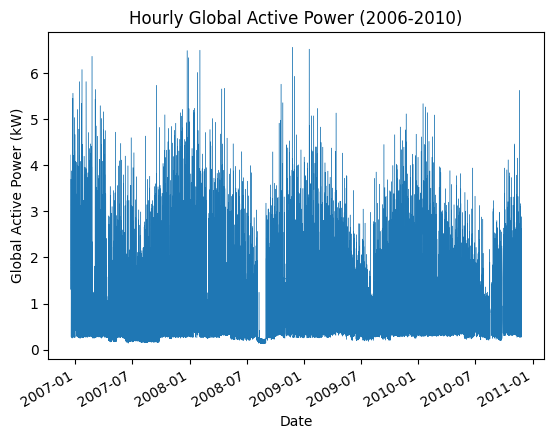

In [10]:
#Plot every hourly reading of global active power across the whole period 
df["global_active_power"].plot(linewidth=0.3)

plt.title("Hourly Global Active Power (2006-2010)")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.show()

## Findings: Hourly Consumption 
- Hourly consumption shows a yearly pattern, with higher and more frequent peaks during the winter months and less usage during summer. 
- Theres a constant base power of around 0.4, representing household appliances that are constantly turned on such as a fridge and stanby devices. 
- Peaks are regularly around 4-6kW representing high power appliances that are on at the same time. 
- A sustained drop in base levels in August 2008, suggests the household was away (e.g., summer holiday). 
- The hourly data is too noisy to see trends clearly, so daily, weekly and monthly averages have been shown below. 

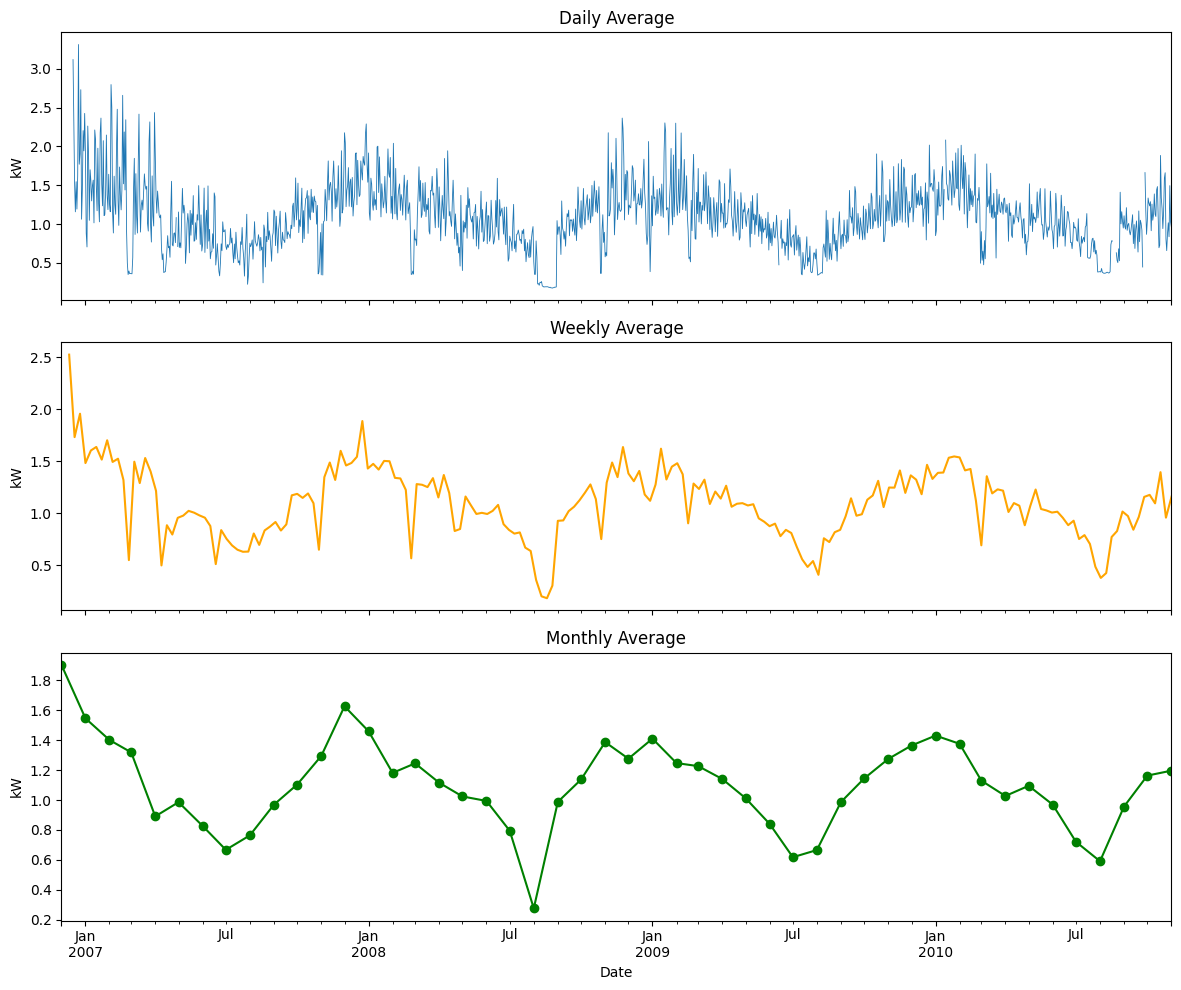

In [11]:
#Resample the hourly data into averages over longer periods
daily = df["global_active_power"].resample("D").mean()
weekly = df["global_active_power"].resample("W").mean()
monthly = df["global_active_power"].resample("MS").mean()

#create 3 charts sharing the same axis
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

daily.plot(ax=axes[0], linewidth=0.6)
axes[0].set_title("Daily Average")

weekly.plot(ax=axes[1], color="orange")
axes[1].set_title("Weekly Average")

monthly.plot(ax=axes[2], color="green", marker="o")
axes[2].set_title("Monthly Average")

#label y-axis on chart
for ax in axes:
    ax.set_ylabel("kW")

plt.xlabel("Date")
plt.tight_layout()
plt.show()    

## Findings: Daily, weekly and monthly averages
- Consumption has a clear annual cycle, peaking in December/January and falling in July/August. 
- August 2008 is the lowest month, consistent with the household being away. 
- December 2006 is the highest. However, it only covers 16th-31st of December, so it is not comparable. 
- The daily chart shows multiple short drops, suggesting brief periods away. 
- There is no strong upward or downward trend. Yearly seasonality is the strongest pattern. 

## Consumption Across Periods 
- Comparing the average consumption by hour of the day, day of the week, month and year to identify when consumption is the highest. 

<function matplotlib.pyplot.show(close=None, block=None)>

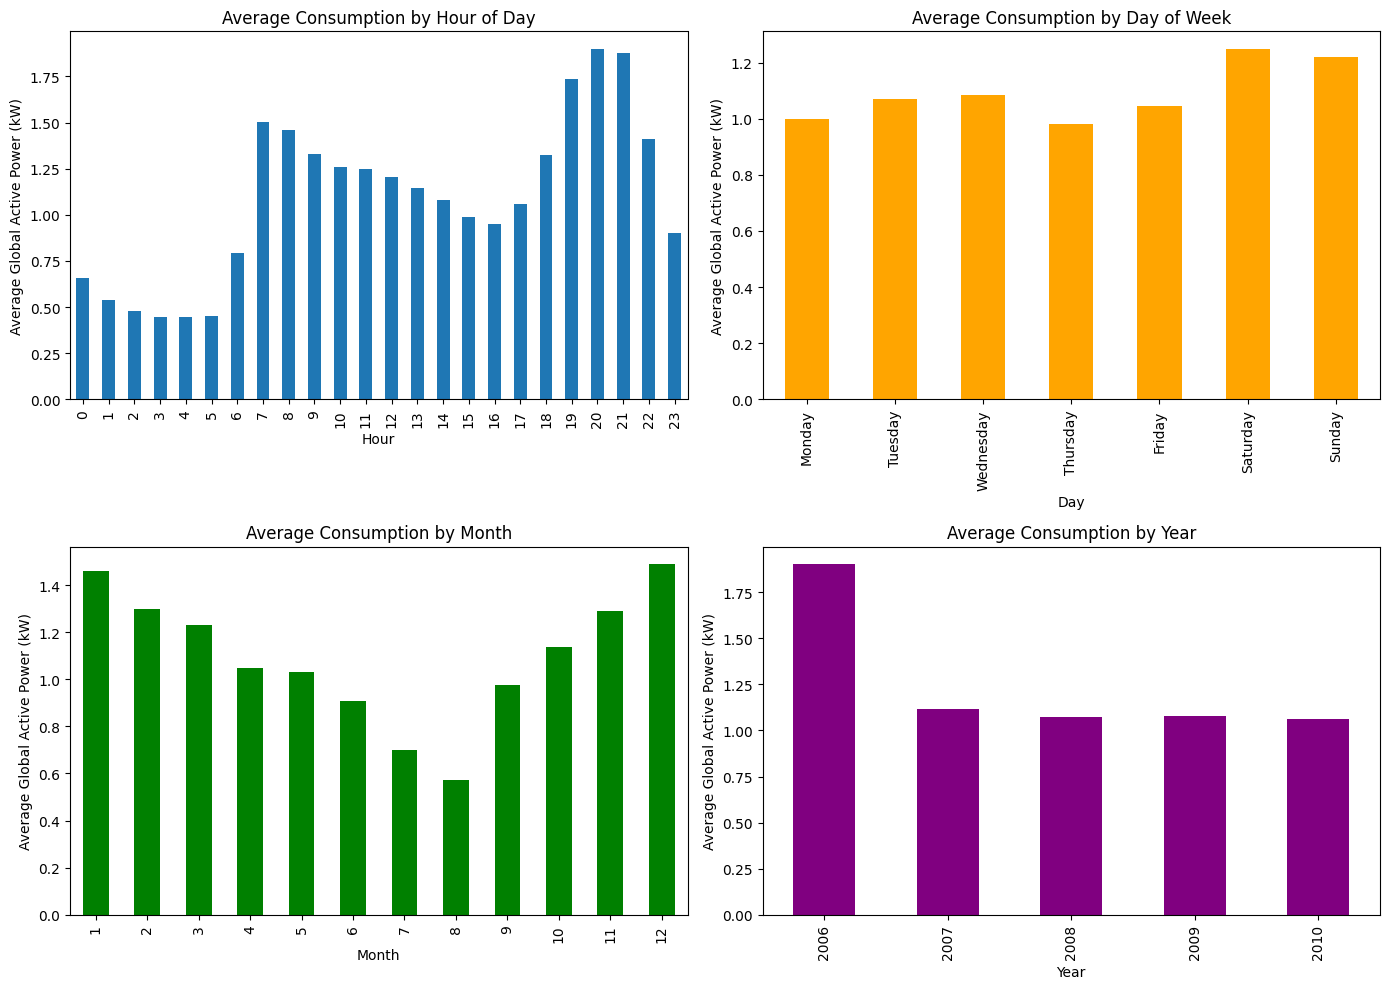

In [13]:
#Add columns that pull timeparts out of datetime index
df["hour"] = df.index.hour
df["day_of_week"] = df.index.day_name()
df["month"] = df.index.month
df["year"] = df.index.year

#order for days of the week 
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

#create 2x2 grid 
fig, axes = plt.subplots(2,2, figsize=(14, 10))

#Average consumption for hour for hour of the day
df.groupby("hour")["global_active_power"].mean().plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Average Consumption by Hour of Day")
axes[0, 0].set_xlabel("Hour")

#Average consumption for each day of the week
df.groupby("day_of_week")["global_active_power"].mean().reindex(day_order).plot(
    kind="bar", ax=axes[0, 1], color="orange" 
)
axes[0, 1].set_title("Average Consumption by Day of Week")
axes[0, 1].set_xlabel("Day")

#Average consumption for each month (1= January, 12 = December)
df.groupby("month")["global_active_power"].mean().plot(kind="bar", ax=axes[1, 0], color="green")
axes[1, 0].set_title("Average Consumption by Month")
axes[1, 0].set_xlabel("Month")

#Average consumption for each year 
df.groupby("year")["global_active_power"].mean().plot(kind="bar", ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Average Consumption by Year")
axes[1, 1].set_xlabel("Year")

#Add the same y-axis to the charts
for ax in axes.flat:
    ax.set_ylabel("Average Global Active Power (kW)")

plt.tight_layout()
plt.show  

## Findings: Consumption Across Periods 
### Hour of the day:
- Consumption is lowest overnight 3-5am, reflecting the base power consumption. 
- A morning peak occurs at 7am, followed by a gradual decline to around 1.00 kW at 4pm.
- The largest peak is at 8pm. 

### Day of the week:
- Weekends are the highest at of 1.2kW on Saturday and Sunday. 
- Weekday consumption is relatively consistent.

### Month: 
- December and January are the highest at over 1.4kW, with August being the lowest at 0.5kW

### Year:
- 2006 appears the highest at 1.9kW, however it only covers December 16-31. Therefore it is not comparable. 
- 2007 to 2010 is relatively stable at around 1.05kW to 1.1kW, with no substantial long term change. 2010 does not include December, so its consumption is slighlty understated. 


## Relationships between measurements 
- Exploring how electrical measurements relate to each other using correlation heatmaps and scatter plots

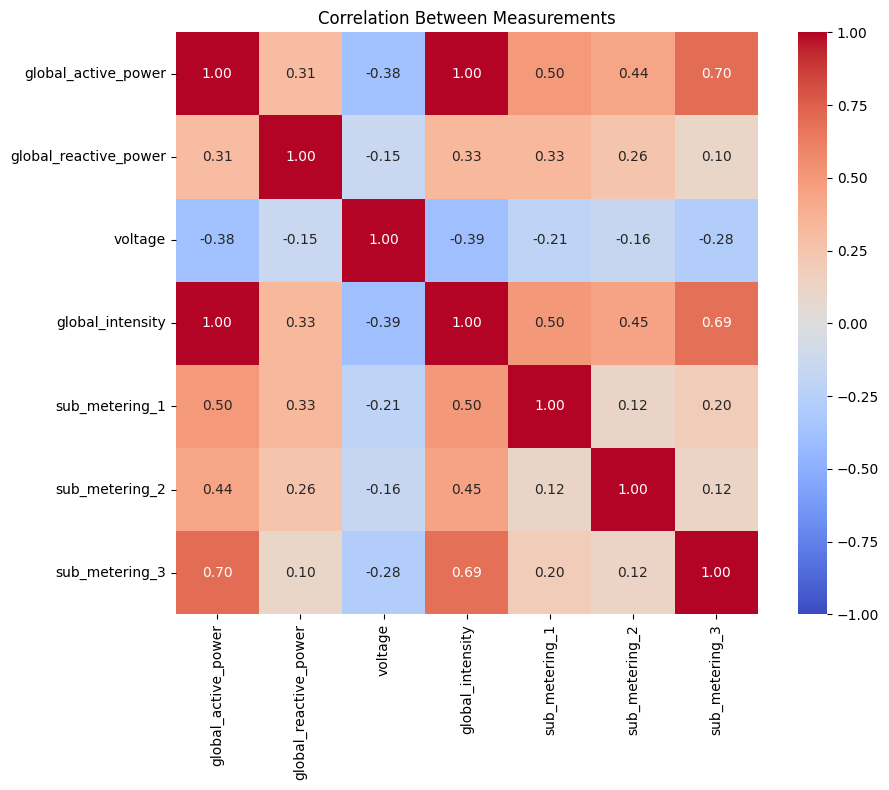

In [14]:
#select original measurement columns 
measurement_cols = [
    "global_active_power", "global_reactive_power", "voltage", "global_intensity", "sub_metering_1", "sub_metering_2", "sub_metering_3"     
]

#calculate correlation between columns 
#values range from -1(move in opposite directions) to +1(move together), 0 = no relationship 
corr = df[measurement_cols].corr()

#draw heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)

plt.title("Correlation Between Measurements")
plt.tight_layout()
plt.show()

## Findings: Correlation between Measurements
- Global active power and global intensity are perfectly correlated (1.00) 
- Voltage has a moderately negative relationship with active power (-0.38), suggesting voltage dips when power demand is high. 
- Sub metering 3 reflects electric water heating and air conditioning. It has the strongest relationship with total consumption at (0.70), suggesting it is the largest driver of household usage.
- Submetering 1 which shows kitchen appliances (0.50) and submetering 2 which shows laundry, fridge and light (0.44) have moderate correlation. 
- The submeters are weakly correlated with each other (0.12 - 0.20), suggesting that they are used independently. 

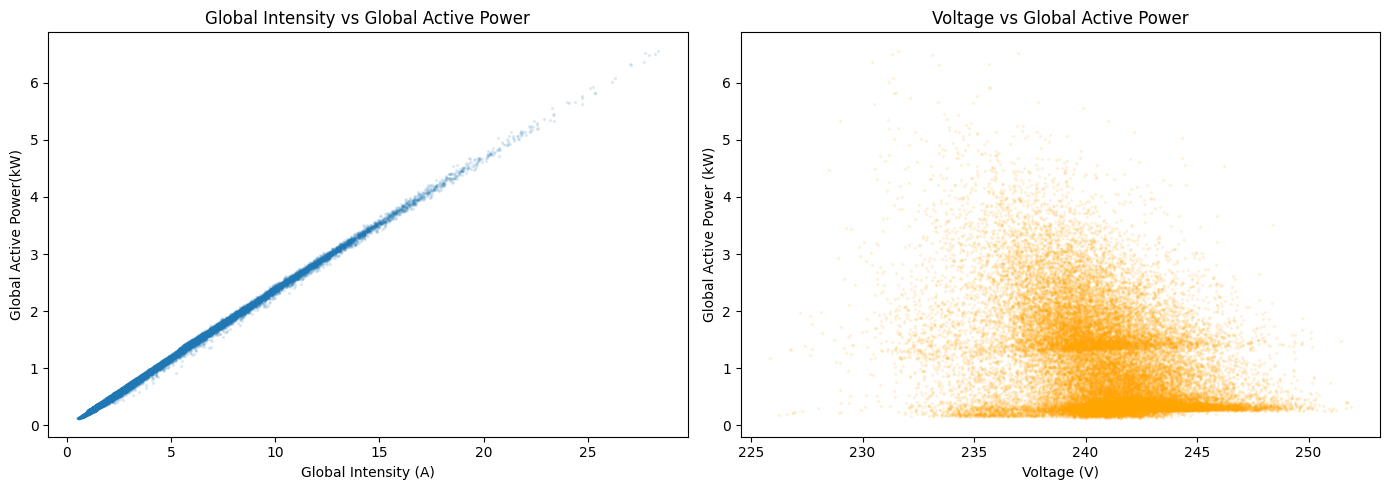

In [16]:
# create 2 charts side by side 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Intensity vs Total Power 
axes[0].scatter(df["global_intensity"], df["global_active_power"], alpha=0.1, s=2)
axes[0].set_title("Global Intensity vs Global Active Power")
axes[0].set_xlabel("Global Intensity (A)")
axes[0].set_ylabel("Global Active Power(kW)")

#Voltage vs Total Power 
axes[1].scatter(df["voltage"], df["global_active_power"], alpha=0.1, s=2, color="orange")
axes[1].set_title("Voltage vs Global Active Power")
axes[1].set_xlabel("Voltage (V)")
axes[1].set_ylabel("Global Active Power (kW)")

plt.tight_layout()
plt.show()

## Findings: Scatter Plot
Global intensity vs global active power
- The points form an almost perfect staright line, confirming the 1.00 correlation, suggesting both variables contain the same information. 

Voltage vs global active power 
- The points form a wide cloud, suggesting voltage is loosely related to consumption. 
- Higher consumption mostly occurs at lower voltages, while the highest voltages occur almost only at low consumption. This matches the moderate negative correlation of (-0.38). Volatge falls slighly when the houshold consumes more power. 
- The base voltage being around 0.2kW represents the housholds contant base load. 
- Voltage alone is not a strong predictor of consumption. 


## Forecasting Future Consumption
- Assessing whther historical consumption shows patterns that could support forecasting using seasonal decomposition and autocorrelation. 

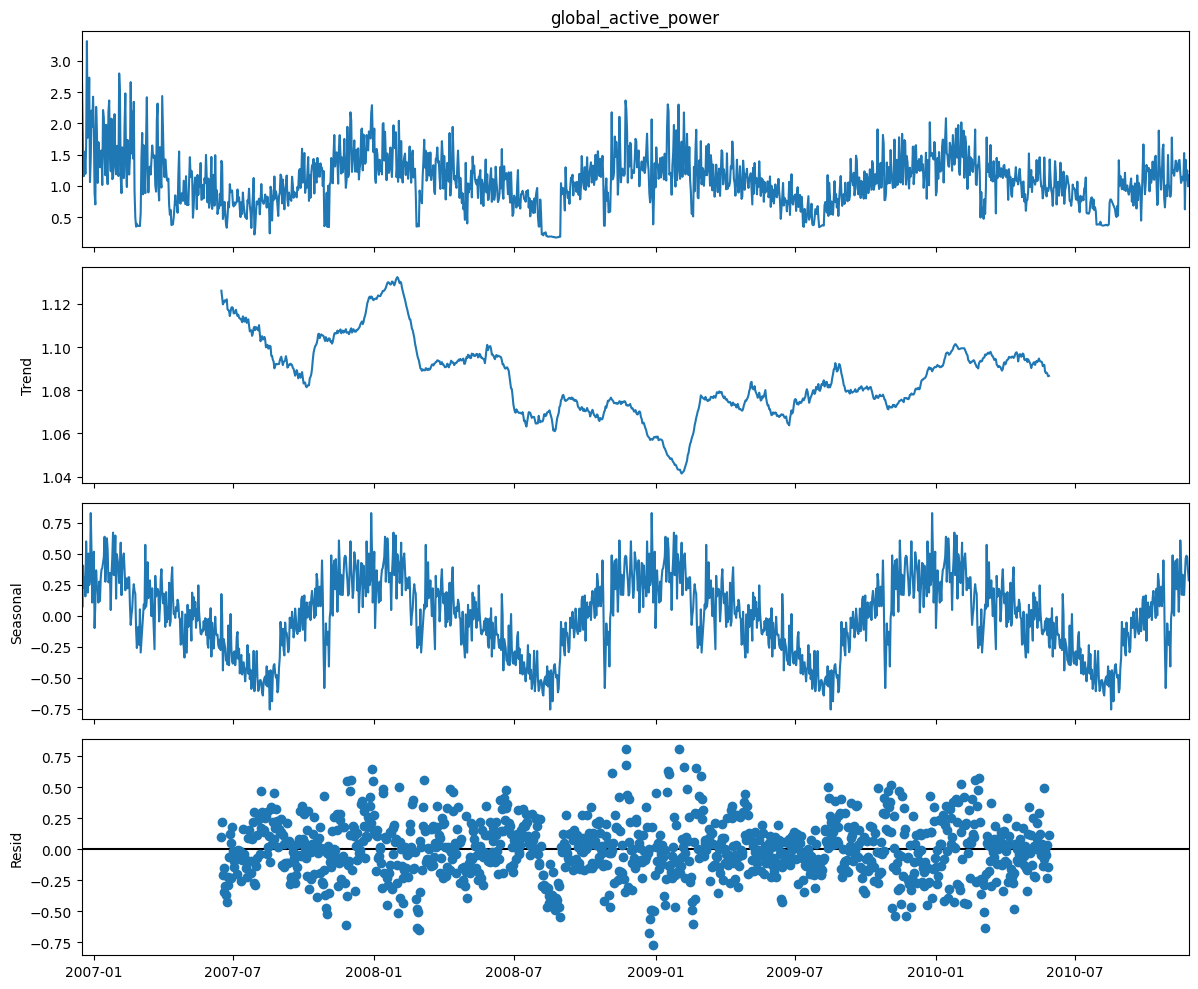

In [17]:
#Tool that splits a time series into trend and seasonality 
from statsmodels.tsa.seasonal import seasonal_decompose

#daily average consumption 
daily = df["global_active_power"].resample("D").mean()

#fill in missing days for decomposition by drawing line 
#filled version is only used for this chart 
daily_filled = daily.interpolate()

#period=365 tells it to look for a pattern that repeats yearly 
decomposition = seasonal_decompose(daily_filled, model="additive", period=365)

#Plot 4 parts: data, trend, seasonal and residual
fig = decomposition.plot()
fig.set_size_inches(12, 10)
plt.tight_layout()
plt.show()

## Findings: Seasonal decomposition
- Trend: The trend varies between 1.04kW and 1.13KW between three years, so there is no substantial increase or decrease in energy use. The dip in late 2008 is caused by the August 2008 holiday period. 
- Seasonality: A strong, regular yearly cycle, around +0.5kW in winter and -0.5kW in summer. Seaonality is the clearest pattern. 
- Residuals: Mostly scatterd around zero within +0.50 and -0.50. This shows that trend and seasonality explain the most clear structure. Larger residuals appear during late 2008 and early 2009, representing events the yearly pattern cannot predict. 